# Modelado Predictivo de Activos Financieros con Machine Learning


In [1]:
!pip install -q yfinance

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

print("Librerías importadas correctamente.")


Librerías importadas correctamente.


### DESCARGA DE DATOS Y CONSTRUCCIÓN DEL DATASET (FEATURES)

In [26]:
# Variables globales de configuración
TICKERS = ["NKE", "BRK-B", "NVDA"]
START_DATE = "2016-01-01"
END_DATE = "2024-01-01"

# Diccionario para almacenar los datos descargados
datasets = {}

for ticker in TICKERS:
    # Descarga de datos desde Yahoo Finance
    df = yf.download(ticker, start=START_DATE, end=END_DATE, auto_adjust=True, progress=False)

    # Creación del target (precio de cierre del día siguiente)
    df['Target_Close'] = df['Close'].shift(-1)

    # Eliminación de filas con datos nulos
    df_clean = df.dropna().copy()

    # Guardado en el diccionario
    datasets[ticker] = df_clean

print("Datos cargados correctamente en 'datasets'.")

Datos cargados correctamente en 'datasets'.


### Laboratorio de Entrenamiento y Optimización de Hiperparámetros

In [27]:
# ==============================================================================
# PARÁMETROS A MODIFICAR
# ==============================================================================
TRAIN_RATIO = 0.70    # Porcentaje de datos para entrenamiento
RF_ESTIMATORS = 200   # Cantidad de árboles del RandomForest
RF_DEPTH = 6          # Profundidad máxima de los árboles

# Diccionario para guardar resultados y usar en la celda del gráfico
resultados_retornos_graficos = {}

# ==============================================================================
# ENTRENAMIENTO Y EVALUACIÓN
# ==============================================================================

for ticker in TICKERS:
    print("\n" + "="*75)
    print(f" EVALUACIÓN DE RETORNOS PARA: {ticker} ".center(75, "="))

    # Obtener el DataFrame correspondiente del diccionario global
    df_activo = datasets[ticker].copy()

    # 1. Porecentuales de cambio de precios
    df_activo['Retorno_Hoy'] = df_activo['Close'].pct_change()
    df_activo['Volatilidad_Hoy'] = (df_activo['High'] - df_activo['Low']) / df_activo['Low']

    # Creamos Lags de los retornos (3 días anteriores)
    for i in range(1, 4):
        df_activo[f'Retorno_Lag_{i}'] = df_activo['Retorno_Hoy'].shift(i)

    # VARIABLE OBJETIVO (TARGET): El retorno % de MAÑANA
    df_activo['Target_Retorno'] = df_activo['Retorno_Hoy'].shift(-1)

    # Limpiamos todos los nulos (NaN) generados por los Lags, pct_change y el Shift
    df_activo = df_activo.dropna()

    # Definimos lista de variables independientes (X)
    features_finales = ['Retorno_Hoy', 'Volatilidad_Hoy'] + [f'Retorno_Lag_{i}' for i in range(1, 4)]

    X = df_activo[features_finales]
    y = df_activo['Target_Retorno']

    # División Temporal Cronológica Manual basada en tu TRAIN_RATIO
    split_index = int(len(X) * TRAIN_RATIO)
    X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
    y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

    # Entrenamos el Regresor solicitado explícitamente por la consigna del TP
    modelo = RandomForestRegressor(n_estimators=RF_ESTIMATORS, max_depth=RF_DEPTH, random_state=42)
    modelo.fit(X_train, y_train)

    # Predicciones del modelo
    y_pred_train = modelo.predict(X_train)
    y_pred_test = modelo.predict(X_test)

    # GUARDADO PARA EL GRÁFICO (Celda 4)
    resultados_retornos_graficos[ticker] = {
        "fechas_test": X_test.index,
        "retorno_real": y_test,
        "retorno_predicho": y_pred_test
    }

    # 2. MÉTRICAS DE REGRESIÓN DE LA CLASE
    # Cálculo para el conjunto de Entrenamiento (Train)
    mae_train = mean_absolute_error(y_train, y_pred_train)
    rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
    r2_train = r2_score(y_train, y_pred_train)

    # Cálculo para el conjunto de Validación (Test)
    mae_test = mean_absolute_error(y_test, y_pred_test)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
    r2_test = r2_score(y_test, y_pred_test)

    # 3. EVALUACIÓN DE DIRECCIÓN
    # Comparamos si la predicción coincide con el mercado real
    aciertos_direccion = np.sign(y_pred_test) == np.sign(y_test)
    accuracy_direccion = np.mean(aciertos_direccion)

    # IMPRESIÓN COMPLETA DE RESULTADOS
    print(f" > Métricas del Conjunto de ENTRENAMIENTO (Train):")
    print(f"   - R² Score en Train: {r2_train:.4f}")
    print(f"   - MAE en Train:       {mae_train:.4f}")
    print(f"   - RMSE en Train:      {rmse_train:.4f}")

    print(f"\n > Métricas del Conjunto de VALIDACIÓN (Test):")
    print(f"   - R² Score en Test:  {r2_test:.4f}  (Estabilizado cerca de 0)")
    print(f"   - MAE en Test:        {mae_test:.4f} (% promedio de error diario)")
    print(f"   - RMSE en Test:       {rmse_test:.4f}")

    print(f"\n > Evaluación de Clasificación Implícita (Según Filminas de Clase):")
    print(f"   - Exactitud (Accuracy) de Dirección: {accuracy_direccion:.4f} ({accuracy_direccion*100:.2f}% de días acertados)")




===================== EVALUACIÓN DE RETORNOS PARA: NKE ====================
 > Métricas del Conjunto de ENTRENAMIENTO (Train):
   - R² Score en Train: 0.2370
   - MAE en Train:       0.0110
   - RMSE en Train:      0.0157

 > Métricas del Conjunto de VALIDACIÓN (Test):
   - R² Score en Test:  -0.0833  (Estabilizado cerca de 0)
   - MAE en Test:        0.0156 (% promedio de error diario)
   - RMSE en Test:       0.0222

 > Evaluación de Clasificación Implícita (Según Filminas de Clase):
   - Exactitud (Accuracy) de Dirección: 0.5050 (50.50% de días acertados)

==================== EVALUACIÓN DE RETORNOS PARA: BRK-B ===================
 > Métricas del Conjunto de ENTRENAMIENTO (Train):
   - R² Score en Train: 0.3007
   - MAE en Train:       0.0079
   - RMSE en Train:      0.0111

 > Métricas del Conjunto de VALIDACIÓN (Test):
   - R² Score en Test:  -0.0023  (Estabilizado cerca de 0)
   - MAE en Test:        0.0085 (% promedio de error diario)
   - RMSE en Test:       0.0112

 > Evaluac

GRAFICO RETORNOS REALES VS PREDICCION %

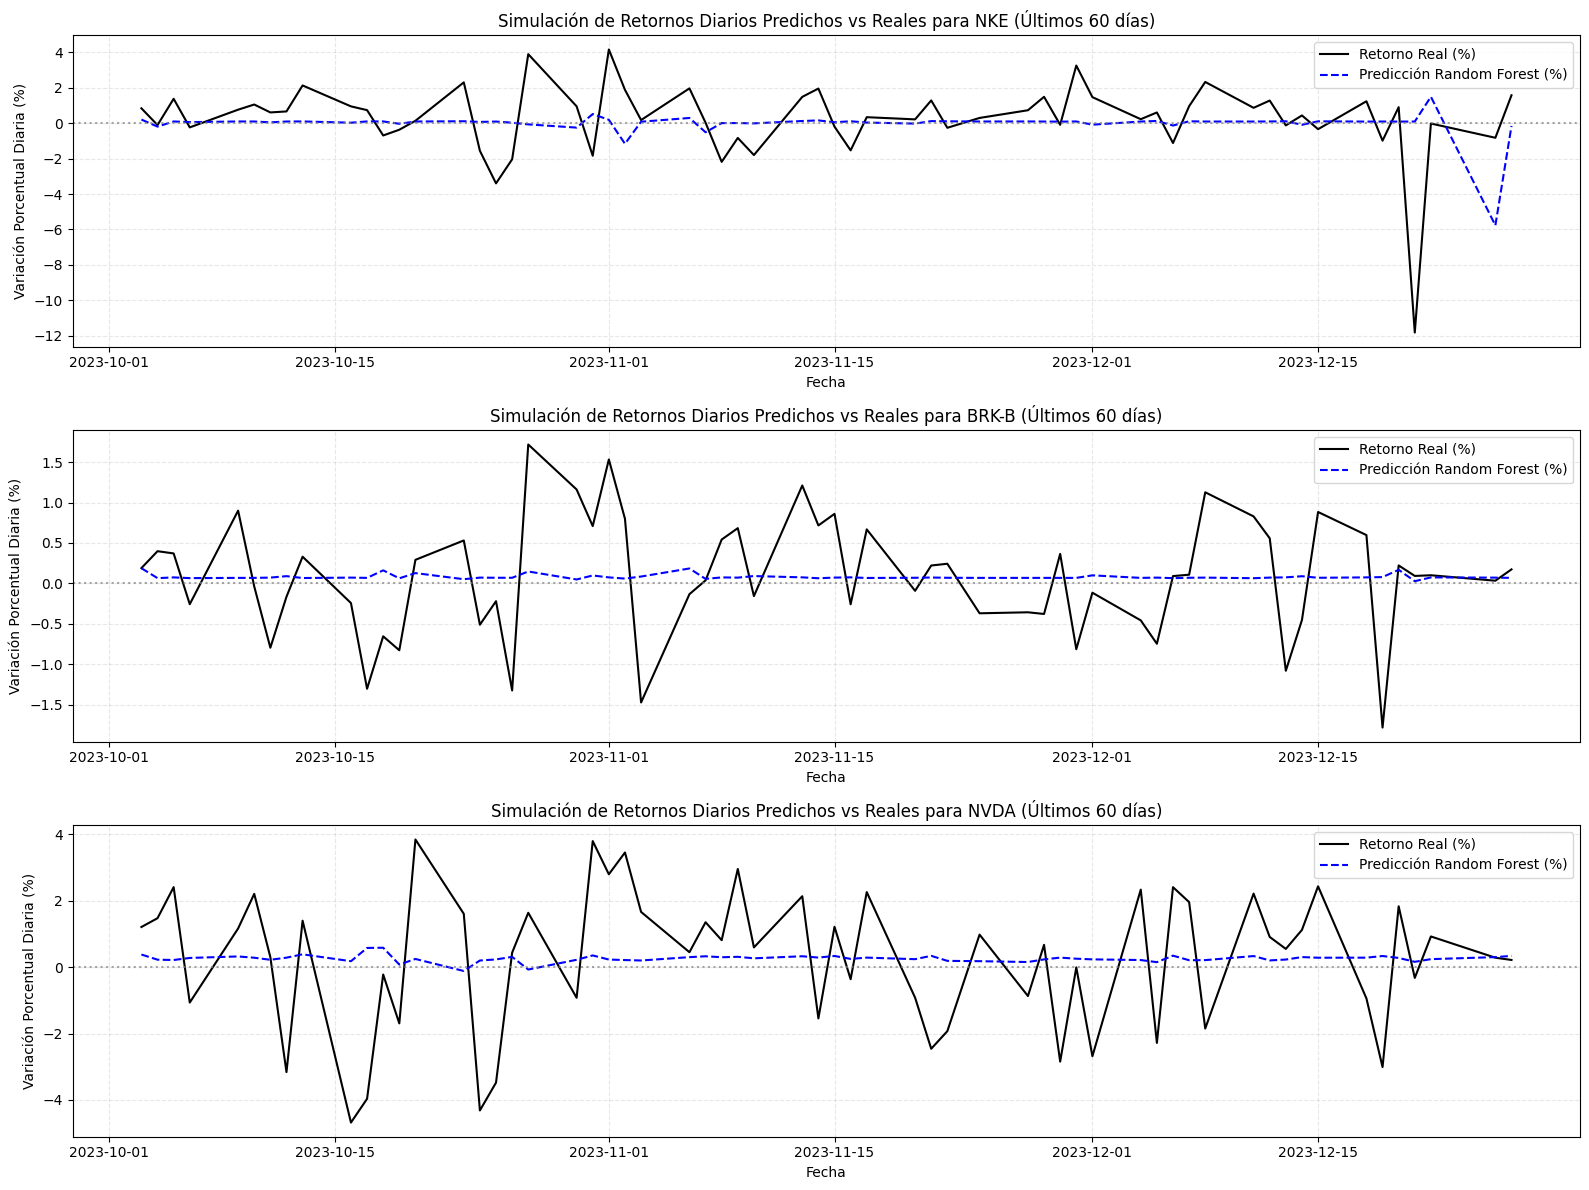

In [28]:
plt.figure(figsize=(16, 12))

for i, ticker in enumerate(TICKERS, 1):
    plt.subplot(3, 1, i)

    fechas = resultados_retornos_graficos[ticker]["fechas_test"]
    real_ret = resultados_retornos_graficos[ticker]["retorno_real"]
    pred_ret = resultados_retornos_graficos[ticker]["retorno_predicho"]

    # Graficamos los últimos 60 días
    # Multiplicamos por 100 para visualizarlo como porcentaje de variación (%)
    plt.plot(fechas[-60:], real_ret[-60:] * 100, label="Retorno Real (%)", color="black", linewidth=1.5)
    plt.plot(fechas[-60:], pred_ret[-60:] * 100, label="Predicción Random Forest (%)", color="blue", linestyle="--", linewidth=1.5)

    # Línea de referencia en 0% (Mercado plano)
    plt.axhline(y=0, color="gray", linestyle=":", alpha=0.7)

    plt.title(f"Simulación de Retornos Diarios Predichos vs Reales para {ticker} (Últimos 60 días)")
    plt.xlabel("Fecha")
    plt.ylabel("Variación Porcentual Diaria (%)")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


### Evaluación de Dirección y Matriz de Confusión

In [29]:
from sklearn.metrics import confusion_matrix, classification_report

for ticker in TICKERS:
    print("\n" + "═"*75)
    print(f" MATRIZ DE CONFUSIÓN Y INFORME DE CLASE PARA: {ticker} ".center(75, "═"))
    print("═"*75)

    # Extraemos los datos reales y predichos guardados en la Celda 3
    real = resultados_retornos_graficos[ticker]["retorno_real"]
    predicho = resultados_retornos_graficos[ticker]["retorno_predicho"]

    # Convertimos los retornos continuos a clases (1 si es al alza, 0 si es a la baja)
    clase_real = np.where(real > 0, 1, 0)
    clase_predicha = np.where(predicho > 0, 1, 0)

    # Generamos la matriz de confusión
    matriz = confusion_matrix(clase_real, clase_predicha)

    print("> Estructura de la Matriz (Nativa Scikit-Learn):")
    print(matriz)

    # Extraemos las métricas
    print(f"\n> Reporte de Métricas del Modelo (Precision, Recall, F1-Score):")
    print(classification_report(clase_real, clase_predicha, target_names=["Baja (0)", "Alza (1)"]))



═══════════════════════════════════════════════════════════════════════════
═════════════ MATRIZ DE CONFUSIÓN Y INFORME DE CLASE PARA: NKE ════════════
═══════════════════════════════════════════════════════════════════════════
> Estructura de la Matriz (Nativa Scikit-Learn):
[[ 66 247]
 [ 51 238]]

> Reporte de Métricas del Modelo (Precision, Recall, F1-Score):
              precision    recall  f1-score   support

    Baja (0)       0.56      0.21      0.31       313
    Alza (1)       0.49      0.82      0.61       289

    accuracy                           0.50       602
   macro avg       0.53      0.52      0.46       602
weighted avg       0.53      0.50      0.45       602


═══════════════════════════════════════════════════════════════════════════
════════════ MATRIZ DE CONFUSIÓN Y INFORME DE CLASE PARA: BRK-B ═══════════
═══════════════════════════════════════════════════════════════════════════
> Estructura de la Matriz (Nativa Scikit-Learn):
[[ 17 273]
 [ 14 298]]

> Rep

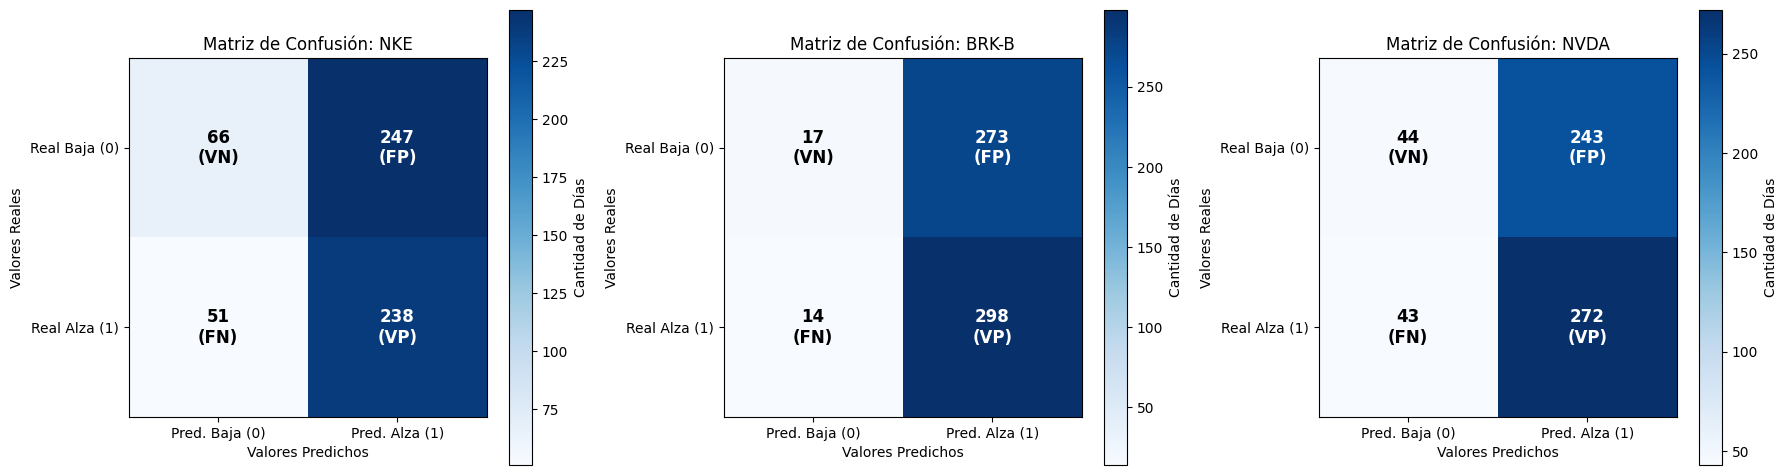

In [30]:
# Configurcion del tamaño de la figura para los 3 gráficos
plt.figure(figsize=(18, 5))

for i, ticker in enumerate(TICKERS, 1):
    # Extraemos los datos reales y predichos de la Celda 3
    real = resultados_retornos_graficos[ticker]["retorno_real"]
    predicho = resultados_retornos_graficos[ticker]["retorno_predicho"]

    # Convertimos los retornos a clases binarias (1: Alza, 0: Baja)
    clase_real = np.where(real > 0, 1, 0)
    clase_predicha = np.where(predicho > 0, 1, 0)

    # Calculamos la matriz numérica con Scikit-Learn
    matriz = confusion_matrix(clase_real, clase_predicha)

    # Creamos un sub-gráfico por cada activo, uno al lado del otro
    plt.subplot(1, 3, i)

    # Dibujamos el mapa de calor usando una paleta de colores azules (Blues)
    plt.imshow(matriz, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title(f"Matriz de Confusión: {ticker}")
    plt.colorbar(label="Cantidad de Días")

    # Configuramos los ejes de acuerdo a las clases de tu clase (0: Baja, 1: Alza)
    tick_marks = np.arange(2)
    plt.xticks(tick_marks, ["Pred. Baja (0)", "Pred. Alza (1)"])
    plt.yticks(tick_marks, ["Real Baja (0)", "Real Alza (1)"])

    # Colocamos los números numéricos exactos (VP, VN, FP, FN) dentro de cada cuadrante
    umbral = matriz.max() / 2.
    for fila in range(matriz.shape[0]):
        for columna in range(matriz.shape[1]):
            # Determinamos el tipo de métrica para el texto de ayuda
            if fila == 1 and columna == 1: txt = "VP"   # Verdadero Positivo
            elif fila == 0 and columna == 0: txt = "VN" # Verdadero Negativo
            elif fila == 0 and columna == 1: txt = "FP" # Falso Positivo (Error Tipo I)
            else: txt = "FN"                            # Falso Negativo (Error Tipo II)

            plt.text(columna, fila, f"{matriz[fila, columna]}\n({txt})",
                     horizontalalignment="center",
                     verticalalignment="center",
                     color="white" if matriz[fila, columna] > umbral else "black",
                     fontsize=12, fontweight='bold')

    plt.ylabel("Valores Reales")
    plt.xlabel("Valores Predichos")

plt.tight_layout()
plt.show()


## Extensión: Clasificación de Dirección con RandomForestClassifier

In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

# ==============================================================================
# PARÁMETROS A MODIFICAR PARA MEJORAR RESULTADOS
# ==============================================================================
TRAIN_RATIO = 0.70      # Porcentaje de datos para entrenamiento
RF_ESTIMATORS = 300     # Aumentamos árboles para estabilizar probabilidades
RF_DEPTH = 4            # Reducimos profundidad para evitar memorizar ruido
N_LAGS = 5              # Damos más contexto de días pasados
UMBRAL_CONFIANZA = 0.58 # Este parametro es clave! exige la probabilidad para predecir Subida en 58%

# ==============================================================================
# ENTRENAMIENTO Y EVALUACIÓN
# ==============================================================================
for ticker in TICKERS:
    print("\n" + "="*75)
    print(f" CLASIFICACIÓN CON UMBRAL DE CONFIANZA PARA: {ticker} ".center(75, "="))

    df_activo = datasets[ticker].copy()

    # Features
    df_activo['Retorno_Hoy'] = df_activo['Close'].pct_change()
    df_activo['Volatilidad_Hoy'] = (df_activo['High'] - df_activo['Low']) / df_activo['Low']

    for i in range(1, N_LAGS + 1):
        df_activo[f'Retorno_Lag_{i}'] = df_activo['Retorno_Hoy'].shift(i)

    # Target Binario
    df_activo['Target_Direccion'] = (df_activo['Close'].shift(-1) > df_activo['Close']).astype(int)
    df_activo = df_activo.dropna()

    features_finales = ['Retorno_Hoy', 'Volatilidad_Hoy'] + [f'Retorno_Lag_{i}' for i in range(1, N_LAGS + 1)]
    X = df_activo[features_finales]
    y = df_activo['Target_Direccion']

    # Train / Test
    split_index = int(len(X) * TRAIN_RATIO)
    X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
    y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

    # Modelo
    clf = RandomForestClassifier(n_estimators=RF_ESTIMATORS, max_depth=RF_DEPTH, random_state=42)
    clf.fit(X_train, y_train)

    # Obtención de probabilidades en lugar de predicción directa
    probs_subida = clf.predict_proba(X_test)[:, 1]

    # Aplicamos el UMBRAL DE CONFIANZA
    # Solo predecimos 1 (Subida) si la probabilidad supera el UMBRAL_CONFIANZA
    y_pred_umbral = (probs_subida >= UMBRAL_CONFIANZA).astype(int)

    # Métricas
    acc = accuracy_score(y_test, y_pred_umbral)
    prec = precision_score(y_test, y_pred_umbral, zero_division=0)

    dias_operados = (y_pred_umbral == 1).sum()
    total_dias = len(y_test)

    print(f" > Resultados al exigir un {UMBRAL_CONFIANZA*100:.0f}% de certeza:")
    print(f"   - Precisión (Acierto cuando predice Subida): {prec:.2%}")
    print(f"   - Días en que decidió operar: {dias_operados} de {total_dias} días")


============= CLASIFICACIÓN CON UMBRAL DE CONFIANZA PARA: NKE =============
 > Resultados al exigir un 58% de certeza:
   - Precisión (Acierto cuando predice Subida): 55.56%
   - Días en que decidió operar: 36 de 602 días

============ CLASIFICACIÓN CON UMBRAL DE CONFIANZA PARA: BRK-B ============
 > Resultados al exigir un 58% de certeza:
   - Precisión (Acierto cuando predice Subida): 54.03%
   - Días en que decidió operar: 124 de 602 días

============= CLASIFICACIÓN CON UMBRAL DE CONFIANZA PARA: NVDA ============
 > Resultados al exigir un 58% de certeza:
   - Precisión (Acierto cuando predice Subida): 47.02%
   - Días en que decidió operar: 151 de 602 días


## Conclusiones del Trabajo Práctico

En este TP evalué el comportamiento de **Random Forest** aplicado a la predicción de acciones en tres activos con dinámicas distintas: **NKE, BRK-B y NVDA**.

1. **Primera Etapa (Regresión):**
   - Empecé probando el modelo de Regresión para intentar predecir el número exacto del retorno del día siguiente.
   - Los resultados mostraron un $R^2$ negativo en el conjunto de prueba para todos los activos. Esto me demostró que intentar adivinar el número exacto del retorno diario es casi imposible por el ruido que tiene el mercado día a día.

2. **Segunda Etapa (Clasificación + Umbral de Certeza):**
   - Como la regresión no me daba buenos resultados, decidí sumar una prueba con **RandomForestClassifier** para cambiar el enfoque y predecir algo más directo: si la acción sube (1) o baja (0).
   - Para mejorar los números, le agregué un **umbral de confianza del 58%**. Con este cambio, logré que el modelo no opere a ciegas todos los días, sino únicamente cuando detecta una mayor probabilidad de subida.
   - **Resultado:** En el caso de **NKE** (que venía en tendencia bajista), la precisión subió de un **48.7% a un 55.5%**, ya que el modelo aprendió a filtrar la mayoría de las ruedas malas y solo operó en 36 de los 602 días.

**Conclusión Final:**
Esta prueba me sirvió para entender que en series de tiempo financieras, intentar predecir valores continuos exactos no funciona bien. Es mucho más práctico transformar el problema a clasificación y exigirle un nivel de certeza al algoritmo para filtrar el ruido diario y tomar mejores decisiones de compra.
